# 06 · The product: one business, one morning

**Question.** What does an owner see, and where does each number come from?

SP0267, 12 December 2024, 8am. The model sees only quotes settled 45+ days earlier. This morning was
chosen because the methods disagree on it; notebook 05 has the comparison over all mornings.

In [1]:
import sys

sys.path.insert(0, "../scripts")

import figures
import pandas as pd
import style

from quote_followup.config import load_settings
from quote_followup.data import load_quotes

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 100)
style.apply()
settings = load_settings("../config.toml")
quotes = load_quotes(settings.data_dir)

from quote_followup import artifacts
from quote_followup.board import explain, followup_board, render, with_outcomes
from quote_followup.scorers import FollowUpModel

morning = pd.Timestamp("2024-12-12 08:00")
model = FollowUpModel(settings.model).fit(quotes, morning)
board = followup_board(model, quotes, "SP0267", morning, settings.followup.daily_capacity)

## 1. The list

In [2]:
print(render(board, settings.followup.daily_capacity))

Call today (top 3):
  quote     work             amount   days waiting  chance of yes  worth today  chance halves in  why
  QU013118  emergency job    $1,738   1.8           84%            $1,452       8.5 days          helps: emergency job, referred by someone; hurts: no reply for 1.8 days
  QU013170  one-off project  $2,769   0.8           45%            $1,251       4.5 days          hurts: one-off project, took 2.1 days to send, found you on their own
  QU013126  one-off project  $13,828  19.7          3%             $365         6.0 days          hurts: no reply for 19.7 days, one-off project, came from a paid ad

Can wait:
  quote     work               amount  days waiting  chance of yes  worth today  chance halves in  why
  QU013112  one-off project    $4,021  15.6          6%             $227         6.5 days          helps: sent within 5 hours; hurts: no reply for 15.6 days, one-off project
  QU013138  recurring service  $233    3.8           66%            $153         5.0 d

- **Chance of yes**: given everything known this morning.
- **Worth today**: chance × amount; the sort key.
- **Chance halves in**: further quiet days until the chance halves.
- **Why**: the largest pushes up or down (at least 0.10 on the log-odds scale).

## 2. From score to list

1. Score at sending (scorecard, section 3).
2. Adjust for days without a reply, by customer type.
3. Convert to a chance.
4. Multiply by the amount.
5. Sort; flag the top 3.
6. Keep the three largest pushes as reasons.

Step 2 by customer source, same work and sending speed:

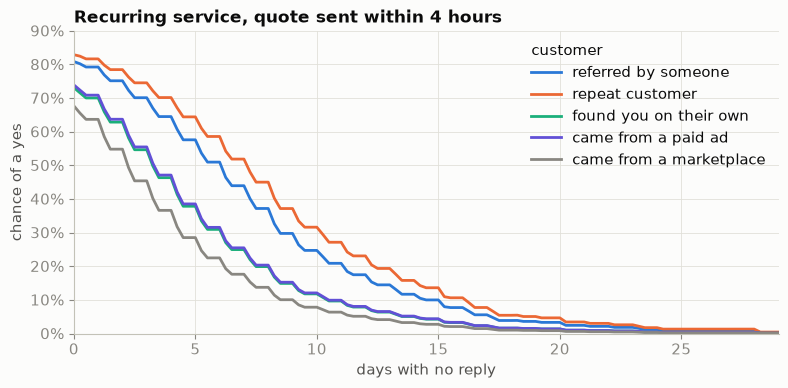

In [3]:
figures.silence_by_customer(model)

## 3. Scorecard

In [4]:
artifacts.scorecard(model)

,points towards a yes,points towards saying no out loud
fact,,
emergency job,0.6930,0.7261
one-off project,-0.4480,-0.8050
recurring service,0.3003,0.2400
came from a marketplace,-0.3115,-0.5882
found you on their own,-0.0514,-0.2287
came from a paid ad,-0.0092,-0.2559
referred by someone,0.3900,0.4760
repeat customer,0.5275,0.7579
each step slower in sending the quote,-0.2023,-0.2101


## 4. Worked example: the top quote

In [5]:
explain(model, board.iloc[0]).to_frame()

,adds to the score
a typical quote starts at,0.7601
type of work: emergency job,0.5897
customer source: referred by someone,0.2834
quote sent after 4.0 hours,0.2009
no reply for 1.8 days,-0.2070
total,1.6271
chance of a yes (from the total),0.8358


The pieces sum exactly to the chance shown. A referred customer usually declines explicitly, so nearly two quiet days cost little.

## 5. What happened

In [6]:
with_outcomes(board, quotes)

,amount,days waiting,chance of yes,worth today,how it ended,reply came
quote_id,,,,,,
QU013118,1737.88,1.799,0.836,1452.470,accepted,2024-12-12 13:50:00
QU013170,2768.75,0.797,0.452,1250.706,accepted,2024-12-13 20:53:00
QU013126,13827.56,19.652,0.026,364.662,expired,NaT
QU013112,4021.24,15.632,0.056,227.012,expired,NaT
QU013138,233.33,3.806,0.657,153.192,declined,2024-12-12 14:40:00
QU013158,167.51,0.720,0.720,120.651,expired,NaT


The top two were accepted within a day and a half. *Biggest first* would have called the \$13.8k quote
(quiet for 20 days, expired); *newest first* a \$168 quote (expired). The third pick, \$13.8k at 3%,
shows the trade-off of ranking by dollars.

## 6. A failure case

In [7]:
other = pd.Timestamp("2024-12-17 08:00")
with_outcomes(followup_board(FollowUpModel(settings.model).fit(quotes, other), quotes, "SP0236", other, 3), quotes)

,amount,days waiting,chance of yes,worth today,how it ended,reply came
quote_id,,,,,,
QU011549,5925.07,4.708,0.404,2393.359,accepted,2024-12-22 21:01:00
QU011550,3423.25,0.531,0.480,1642.167,expired,NaT
QU011507,5889.44,5.705,0.221,1298.944,expired,NaT
QU011528,2619.98,3.778,0.438,1148.141,accepted,2024-12-23 15:19:00
QU011523,6204.94,16.803,0.035,218.952,expired,NaT
QU011526,252.74,1.808,0.657,166.071,expired,NaT
QU011522,507.55,5.445,0.232,117.787,expired,NaT
QU011520,3155.72,28.583,0.015,46.275,expired,NaT


Second, \$3.4k at 48%: expired. Fourth, \$2.6k at 44%: accepted. Near-equal chances are close to a coin toss.

## 7. Replay

![The list replayed every four hours for three weeks](../assets/board.gif)

## Limits

- Ranks likely yeses, not persuadable ones: there is no record of follow-up calls. A randomised hold-out would measure uplift.
- The order matches *days waiting × amount*; the model's value is calibrated chances and reasons.
- Synthetic data.

## Next steps

- **Measure what a call changes:** hold out a random share of quotes from follow-up for a few weeks and
  fit an uplift model, so the list ranks the quotes a call can actually move.
- **Track every run in MLflow:** settings, seeds, a data fingerprint, metrics, charts and the model.
- **Fix the groups still off:** recurring quotes from repeat customers are rated too low after a few quiet days.
- **Later:** an LLM to draft each follow-up message; clustering to segment businesses and customers.

## How it's built

One job per module behind a shared interface (SOLID); every setting in `config.toml`, seeded random
steps and pinned library versions; 21 unit tests and CI (lint, tests, Docker build) on every push;
`docker compose up` runs JupyterLab and the full rebuild. Details in the README and DESIGN.md.